# 05 · End to End on a Model

The real thing. We quantize **every** 2-D weight of `distilgpt2` and measure the full
trade-off: downstream quality (logit similarity and perplexity on held-out text), the
memory saved, and the speed — then validate the from-scratch path against torch's own
quantizer. int8 nearly matches fp32; int4 is close with per-channel scales and degrades
with naive per-tensor; memory drops to a quarter and an eighth.

In [1]:
import sys
from pathlib import Path

_root = Path.cwd()
if not (_root / "src").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import json
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

from src.artifacts import save_figure, save_json
from src.config import load_settings

settings = load_settings()
np.random.seed(settings.seed)
print("settings:", settings.model_dump())

settings: {'seed': 0, 'bit_widths': [8, 4], 'granularity': 'per_channel', 'channel_axis': 1, 'scheme': 'absmax', 'clip_percentile': 99.9, 'clip_sigma': 6.0, 'outlier_sigma': 6.0, 'model_name': 'distilgpt2', 'synthetic': {'rows': 256, 'cols': 256, 'outlier_scale': 10.0, 'n_outliers': 1}}


In [2]:
import time

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

from src.bits.widths import packed_bytes, size_ratio
from src.evaluation.downstream import fake_quantize_2d_weights

tokenizer = AutoTokenizer.from_pretrained(settings.model_name)
model = AutoModelForCausalLM.from_pretrained(settings.model_name).eval()

prompts = [
    "The capital of France is",
    "Quantization lets a large model run on a",
    "In the beginning the universe was",
    "She opened the door and found",
]
eval_text = (
    "Quantization stores each weight in fewer bits so a model that needed a datacenter "
    "can run on a laptop, with surprisingly little loss in quality when done carefully."
)
enc = [tokenizer(p, return_tensors="pt") for p in prompts]
eval_ids = tokenizer(eval_text, return_tensors="pt")


def logits_and_loss(m):
    with torch.no_grad():
        logits = [m(**e).logits.flatten() for e in enc]
        loss = m(**eval_ids, labels=eval_ids["input_ids"]).loss.item()
    return logits, loss


ref_logits, ref_loss = logits_and_loss(model)
print(f"fp32 perplexity on eval text: {np.exp(ref_loss):.2f}")

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


fp32 perplexity on eval text: 184.78


## Quality across bit-widths

For each configuration we quantize the model, then compare its logits to fp32 (cosine,
averaged over prompts) and its perplexity on the eval text. int8 quantizes **every** weight
including the token embedding. int4 keeps the embedding in fp32 — int4 is fine for the
transformer blocks but *catastrophic* on the tied embedding/`lm_head`, a concrete lesson
that *what* you quantize matters as much as how.

In [3]:
configs = [
    ("int8 per-channel", dict(bits=8, scheme="absmax", granularity="per_channel", axis=1, skip=())),
    ("int4 per-channel", dict(bits=4, scheme="absmax", granularity="per_channel", axis=1, skip=("wte", "wpe"))),
    ("int4 per-tensor (naive)", dict(bits=4, scheme="absmax", granularity="per_tensor", skip=("wte", "wpe"))),
]

rows = [{"config": "fp32", "bits": 32, "logit_cosine": 1.0, "perplexity": float(np.exp(ref_loss))}]
for name, kw in configs:
    qm = fake_quantize_2d_weights(model, **kw)
    q_logits, q_loss = logits_and_loss(qm)
    cosines = [
        torch.nn.functional.cosine_similarity(a, b, dim=0).item()
        for a, b in zip(ref_logits, q_logits)
    ]
    rows.append({
        "config": name,
        "bits": kw["bits"],
        "logit_cosine": float(np.mean(cosines)),
        "perplexity": float(np.exp(q_loss)),
    })
    del qm
    print(f"{name:26s}  cosine {np.mean(cosines):.5f}   perplexity {np.exp(q_loss):.2f}")

quality = pd.DataFrame(rows)
print(quality.to_string(index=False))

int8 per-channel            cosine 0.99990   perplexity 188.55


int4 per-channel            cosine 0.99121   perplexity 533.95


int4 per-tensor (naive)     cosine 0.97476   perplexity 6341.17
                 config  bits  logit_cosine  perplexity
                   fp32    32      1.000000  184.781034
       int8 per-channel     8      0.999895  188.549814
       int4 per-channel     4      0.991210  533.949409
int4 per-tensor (naive)     4      0.974761 6341.172177


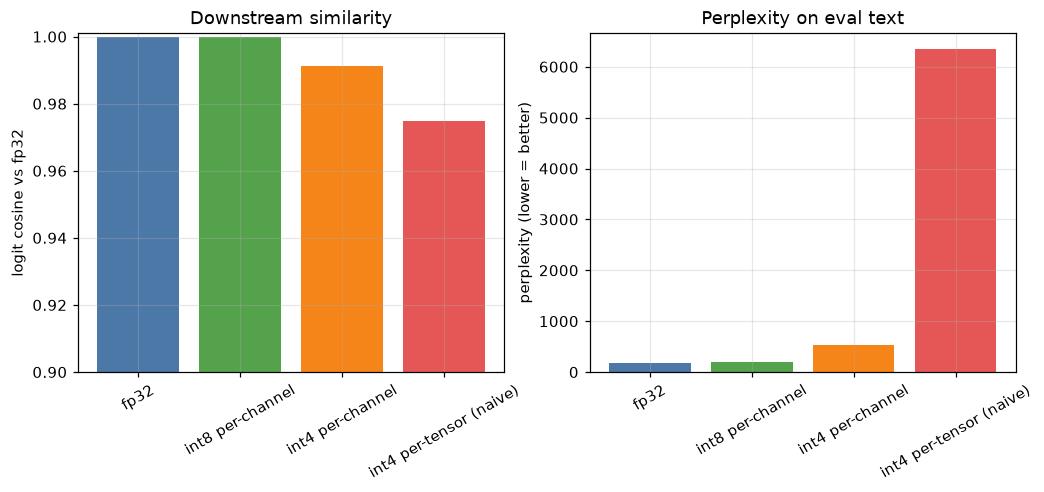

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
labels = quality["config"].tolist()
colors = ["#4C78A8", "#54A24B", "#F58518", "#E45756"]
ax1.bar(labels, quality["logit_cosine"], color=colors)
ax1.set_ylim(min(0.9, quality["logit_cosine"].min() - 0.02), 1.001)
ax1.set_ylabel("logit cosine vs fp32")
ax1.set_title("Downstream similarity")
ax1.tick_params(axis="x", rotation=30)
ax2.bar(labels, quality["perplexity"], color=colors)
ax2.set_ylabel("perplexity (lower = better)")
ax2.set_title("Perplexity on eval text")
ax2.tick_params(axis="x", rotation=30)
save_figure(fig, "05_quality_vs_bits")
plt.show()

## Memory saved

The size claim, on the whole model: quantize every 2-D weight (1-D parameters — biases,
layer norms — stay fp32). The footprint falls to roughly a quarter at int8 and an eighth
at int4. (The int4 *quality* run above spared the embedding, so its practical saving is a
little smaller — size and quality pull in opposite directions on that one matrix.)

total params 81,912,576  (2-D quantizable: 81,851,136, 100%)
fp32:   312.5 MiB   (1.000x)
int8:    78.3 MiB   (0.251x)
int4:    39.3 MiB   (0.126x)


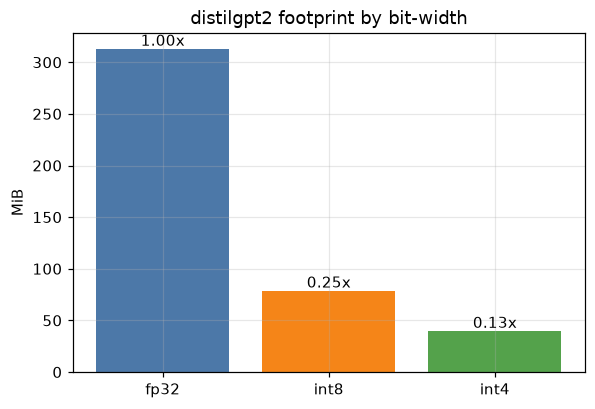

In [5]:
def model_footprint_mib(m, bits):
    total = 0
    for _, p in m.named_parameters():
        total += packed_bytes(p.numel(), bits) if p.ndim == 2 else p.numel() * 4
    return total / (1024 * 1024)

n_params = sum(p.numel() for _, p in model.named_parameters())
n_2d = sum(p.numel() for _, p in model.named_parameters() if p.ndim == 2)
mem = {"fp32": model_footprint_mib(model, 32), "int8": model_footprint_mib(model, 8),
       "int4": model_footprint_mib(model, 4)}
print(f"total params {n_params:,}  (2-D quantizable: {n_2d:,}, {n_2d / n_params:.0%})")
for k, v in mem.items():
    print(f"{k}: {v:7.1f} MiB   ({v / mem['fp32']:.3f}x)")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(list(mem), list(mem.values()), color=["#4C78A8", "#F58518", "#54A24B"])
for x, v in enumerate(mem.values()):
    ax.text(x, v, f"{v / mem['fp32']:.2f}x", ha="center", va="bottom")
ax.set_ylabel("MiB")
ax.set_title("distilgpt2 footprint by bit-width")
save_figure(fig, "05_memory")
plt.show()

## Validate against a reference, and check speed

The from-scratch zero-point int8 path agrees with torch's own quantizer to within one
quantization level. Speed is unchanged here because fake quantization dequantizes back to
float before the matmul — real low-bit speed needs integer hardware kernels (noted, not
overclaimed).

In [6]:
from src.models.weights import load_model_weights
from src.reference.compare import compare_to_torch

sample = load_model_weights(settings.model_name)
sample_w = sample[next(k for k in sample if k.endswith("mlp.c_fc.weight"))]
ref = compare_to_torch(sample_w)
print(f"reference check: max abs diff {ref['max_abs_diff']:.3e}  vs one quant step {ref['quant_step']:.3e}")
assert ref["max_abs_diff"] <= 1.5 * ref["quant_step"]

def timed_forward():
    with torch.no_grad():
        model(**eval_ids)

t0 = time.perf_counter()
for _ in range(5):
    timed_forward()
fwd_ms = (time.perf_counter() - t0) / 5 * 1000
print(f"fp32 forward pass: {fwd_ms:.1f} ms")

results = {
    "quality": rows,
    "total_params": int(n_params),
    "quantizable_2d_params": int(n_2d),
    "memory_mib": mem,
    "memory_ratio_int8": mem["int8"] / mem["fp32"],
    "memory_ratio_int4": mem["int4"] / mem["fp32"],
    "reference_max_abs_diff": ref["max_abs_diff"],
    "reference_quant_step": ref["quant_step"],
    "fp32_forward_ms": fwd_ms,
}

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

reference check: max abs diff 0.000e+00  vs one quant step 2.983e-02


fp32 forward pass: 85.3 ms


## Takeaway

On a model you can run on a laptop: **int8 per-channel is nearly free** (logit cosine
≈ 1, perplexity essentially unchanged, memory cut to a quarter). **int4 per-channel**
degrades but stays far ahead of **int4 naive per-tensor**, which collapses — the outlier
problem, now measured on a real model. Simple absmax int4 leaves a real gap; closing it is
exactly what calibration-based methods (GPTQ, AWQ) do — see notebook 06. Always check both
reconstruction error *and* downstream quality: int8's tiny reconstruction error did predict
preserved behavior, but only measuring perplexity reveals how far int4 actually moves.

In [7]:
path = save_json(results, "05_results")
print("saved", path)
quality

saved /workspaces/quantization_101/outputs/data/05_results.json


,config,bits,logit_cosine,perplexity
0,fp32,32,1.000000,184.781034
1,int8 per-channel,8,0.999895,188.549814
2,int4 per-channel,4,0.991210,533.949409
3,int4 per-tensor (naive),4,0.974761,6341.172177
